# Лабораторная работа 3. Структуры данных

**Опора:** лекция 6.

Сначала реализуются массив фиксированной ёмкости и односвязный список, затем
два стека поверх этих структур. После этого реализуются две хеш-функции и
хеш-таблица с цепочками. Генерация данных, тесты, измерения и графики находятся
в пакете `labkit` рядом с ноутбуком.

In [1]:
import sys
from pathlib import Path

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "labkit").is_dir():
        sys.path.insert(0, str(candidate))
        break

import labkit as lk

print("Режим:", lk.CONFIG.name, "| размеры структур:", lk.sizes())

Режим: быстрый | размеры структур: [1000, 2000, 4000, 8000, 16000, 32000]


/home/klyce/Documents/DSA_IDU_26/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Задача 1. Массив фиксированной ёмкости

Структура хранит последовательность элементов во внутреннем хранилище, созданном
один раз на `capacity` элементов. После создания длина хранилища не меняется:
добавление и удаление меняют только счётчик занятых ячеек и сдвигают элементы.

Поддерживаются добавление в конец, вставка по индексу, удаление по индексу и
доступ по индексу. Выход за границы и переполнение — ошибка.

- **Требование:** методы, меняющие длину внутреннего списка (`append`, `insert`,
  `pop`, `remove`, `clear` у самого списка), не используются. Тест проверяет это
  отдельно.

In [27]:
class FixedArray:
    """Массив фиксированной ёмкости.

    Хранилище создаётся один раз на capacity ячеек и больше не меняет длину.
    Число занятых ячеек хранится отдельно.
    """

    def __init__(self, capacity):
        self.capacity = capacity
        self.data = [None] * capacity
        self.size = 0
        self.cursor = 0

    def __len__(self):
        return self.size

    def get(self, index):
        """Значение по индексу; выход за границу — ошибка."""
        # TODO: реализовать
        if index > self.size:
            raise Exception("выход за границу — ошибка")

        return self.data[index]

        raise NotImplementedError("FixedArray.get")

    def append(self, value):
        """Добавить в конец; переполнение — ошибка."""
        # TODO: реализовать

        if self.cursor >= self.capacity:
            Exception("переполнение — ошибка")

        self.data[self.cursor] = value
        self.cursor += 1
        self.size += 1

        return

        raise NotImplementedError("FixedArray.append")

    def insert(self, index, value):
        """Вставить по индексу со сдвигом вправо."""
        # TODO: реализовать

        if index > self.size:
            raise Exception("выход за границу — ошибка")

        for i in range(self.size - 1, index - 1, -1):
            self.data[i + 1] = self.data[i]
        self.data[index] = value
        self.cursor += 1
        self.size += 1

        return

        raise NotImplementedError("FixedArray.insert")

    def remove_at(self, index):
        """Удалить по индексу со сдвигом влево, вернуть удалённое значение."""
        # TODO: реализовать

        if index >= self.size:
            raise Exception("выход за границу — ошибка")

        deleted_element = self.data[index]

        for i in range(index, self.size):
            self.data[i] = self.data[i + 1]

        self.cursor -= 1
        self.size -= 1

        return deleted_element

        raise NotImplementedError("FixedArray.remove_at")

In [28]:
lk.check_fixed_array(FixedArray)

Массив фиксированной ёмкости
  [ok]   новый массив пуст
    Input: {'capacity': 3}
    Output: 0
    Expected: 0
  [ok]   добавление в конец
    Input: {'before': [], 'call': 'append(10), append(20), append(30)', 'capacity': 3}
    Output: {'after': [10, 20, 30], 'return': [None, None, None]}
    Expected: {'after': [10, 20, 30], 'return': 'не проверяется'}
  [ok]   переполнение — ошибка
    Input: {'before': [10, 20, 30], 'call': 'append(40)', 'capacity': 3}
    Output: IndexError: list assignment index out of range
    Expected: исключение Exception
  [ok]   подготовка массива
    Input: {'before': [], 'call': 'append(1), append(3)', 'capacity': 6}
    Output: {'after': [1, 3], 'return': [None, None]}
    Expected: {'after': [1, 3], 'return': 'не проверяется'}
  [ok]   вставка в середину
    Input: {'before': [1, 3], 'call': 'insert(1, 2)', 'capacity': 6}
    Output: {'after': [1, 2, 3], 'return': None}
    Expected: {'after': [1, 2, 3], 'return': 'не проверяется'}
  [ok]   вставка в

## Задача 2. Односвязный список

Реализовать односвязный список. Поддерживаются вставка в начало, вставка
в конец, удаление первого элемента и доступ по индексу.

In [40]:
class Node:
    def __init__(self, value):
        self.value = value
        self.next = None


class SinglyLinkedList:
    """Односвязный список."""

    def __init__(self):
        self.head = None
        self.tail = None
        self.size = 0

    def __len__(self):
        return self.size


    def append(self, value):
        """Добавить в конец."""

        new_node = Node(value)

        if self.head is None:
            self.head = new_node
            self.tail = new_node
        else:
            self.tail.next = new_node
            self.tail = new_node

        self.size += 1

        return

        raise NotImplementedError("SinglyLinkedList.append")

    def prepend(self, value):
        """Добавить в начало."""

        new_node = Node(value)

        if self.head is None:
            self.head = new_node
            self.tail = new_node
        else:
            old_head = self.head

            self.head = new_node
            self.head.next = old_head

        self.size += 1

        return

        raise NotImplementedError("SinglyLinkedList.prepend")

    def get(self, index):
        """Значение по индексу; выход за границу — ошибка."""

        if index < 0 or index >= self.size:
            raise Exception("выход за границу — ошибка")
        
        cursor = self.head
        for i in range(index):
            cursor = cursor.next
        
        return cursor.value

        raise NotImplementedError("SinglyLinkedList.get")

    def remove_first(self):
        """Удалить первый элемент и вернуть его; пустой список — ошибка."""

        if self.head is None:
            raise Exception("пустой список — ошибка")
        else:
            old_value = self.head.value
            self.head = self.head.next
        
        self.size -= 1

        return old_value

        raise NotImplementedError("SinglyLinkedList.remove_first")

In [41]:
lk.check_linked_list(SinglyLinkedList, "Односвязный список")

Односвязный список
  [ok]   новый список пуст
    Input: 'создание пустого списка'
    Output: 0
    Expected: 0
  [ok]   добавление в конец
    Input: {'before': [], 'call': 'append(1), append(2), append(3)'}
    Output: {'after': [1, 2, 3], 'return': [None, None, None]}
    Expected: {'after': [1, 2, 3], 'return': 'не проверяется'}
  [ok]   вставка в начало
    Input: {'before': [1, 2, 3], 'call': 'prepend(0)'}
    Output: {'after': [0, 1, 2, 3], 'return': None}
    Expected: {'after': [0, 1, 2, 3], 'return': 'не проверяется'}
  [ok]   доступ по индексу
    Input: {'before': [0, 1, 2, 3], 'call': 'get(0), get(3)'}
    Output: (0, 3)
    Expected: (0, 3)
  [ok]   чтение за границей — ошибка
    Input: {'before': [0, 1, 2, 3], 'call': 'get(4)'}
    Output: Exception: выход за границу — ошибка
    Expected: исключение Exception
  [ok]   удаление первого
    Input: {'before': [0, 1, 2, 3], 'call': 'remove_first()'}
    Output: {'after': [1, 2, 3], 'return': 0}
    Expected: {'after': [1,

## Задача 3. Стек на подготовленных структурах

Реализуются **два стека**: один поверх собственного массива фиксированной
ёмкости, другой поверх собственного связного списка. Использовать нужно
структуры из задач 1 и 2, а не список Python.

Поддерживаются добавление элемента, извлечение последнего добавленного, просмотр
последнего добавленного и проверка на пустоту. Извлечение из пустого стека —
ошибка.

In [50]:
class ArrayStack:
    """Стек поверх собственного массива фиксированной ёмкости."""

    def __init__(self, capacity):
        self.data = FixedArray(capacity)
        self.cursor = -1

    def __len__(self):
        return len(self.data)

    def is_empty(self):

        return len(self.data) == 0

        raise NotImplementedError("ArrayStack.is_empty")

    def push(self, value):

        self.data.append(value)
        self.cursor += 1

        return

        raise NotImplementedError("ArrayStack.push")

    def pop(self):
        """Извлечь последний добавленный; пустой стек — ошибка."""

        if self.is_empty():
            raise Exception("пустой стек — ошибка")
        else:
            return_value = self.data.get(self.cursor)
            self.data.remove_at(self.cursor)
            self.cursor -= 1

            return return_value


        raise NotImplementedError("ArrayStack.pop")

    def top(self):
        """Посмотреть последний добавленный; пустой стек — ошибка."""

        if len(self.data) == 0:
            raise Exception("пустой стек — ошибка")
        else:
            return self.data.get(self.cursor)

        raise NotImplementedError("ArrayStack.top")


class LinkedStack:
    """Стек поверх собственного связного списка.

    Ёмкость связному списку не нужна, но аргумент принимается: так обе
    реализации создаются одинаково.
    """

    def __init__(self, capacity=None):
        # TODO: использовать реализованный выше связный список
        self.data = SinglyLinkedList()

    def __len__(self):
        return len(self.data)

    def is_empty(self):

        return len(self.data) == 0

        raise NotImplementedError("LinkedStack.is_empty")

    def push(self, value):

        self.data.prepend(value)

        return

        raise NotImplementedError("LinkedStack.push")

    def pop(self):

        if len(self.data) == 0:
            raise Exception("пустой стек — ошибка")
        else:
            return_value = self.data.head.value
            self.data.remove_first()

            return return_value

        raise NotImplementedError("LinkedStack.pop")

    def top(self):

        if len(self.data) == 0:
            raise Exception("пустой стек — ошибка")
        else:
            return self.data.head.value

        raise NotImplementedError("LinkedStack.top")

In [52]:
lk.check_stack(ArrayStack, "Стек на массиве")
lk.check_stack(LinkedStack, "Стек на связном списке")

Стек на массиве
  [ok]   новый стек пуст
    Input: {'call': 'is_empty()', 'capacity': 8}
    Output: True
    Expected: True
  [ok]   после push стек не пуст
    Input: {'before': {'empty': True, 'size': 0, 'top': None}, 'call': 'push(10)'}
    Output: {'after': {'empty': False, 'size': 1, 'top': 10}, 'return': None}
    Expected: {'after': {'empty': False, 'size': 1, 'top': 10}, 'return': 'не проверяется'}
  [ok]   top показывает последний добавленный
    Input: {'before': {'empty': False, 'size': 1, 'top': 10}, 'call': 'push(20), top()'}
    Output: {'after': {'empty': False, 'size': 2, 'top': 20}, 'return': None}
    Expected: {'after': {'empty': False, 'size': 2, 'top': 20}, 'return': 'не проверяется'}
  [ok]   pop возвращает последний добавленный
    Input: {'before': {'empty': False, 'size': 2, 'top': 20}, 'call': 'pop()'}
    Output: {'after': {'empty': False, 'size': 1, 'top': 10}, 'return': 20}
    Expected: {'after': {'empty': False, 'size': 1, 'top': 10}, 'return': 20}
  [o

## Задача 4. Две хеш-функции для строк

Ключи в этой работе строковые. Реализовать **обе** функции: они различаются
только тем, учитывают ли порядок символов, и это различие — предмет
эксперимента.

**Сумма кодов** — намеренно плохая функция:

```text
h(s) = (сумма кодов символов s) mod m
```

**Полиномиальный хеш** — схема Горнера с основанием `X`, выданным в шаблоне:

```text
h = 0
для каждого символа c строки: h = (h * X + ord(c)) mod m
```

Обе функции принимают ключ и число слотов `m` и возвращают целое из
диапазона `0 … m-1`.

In [55]:
X = 31   # основание полиномиального хеша


def hash_sum(key, m):
    """Сумма кодов символов по модулю m.

    Порядок символов эта функция не учитывает — в этом и состоит предмет
    сравнения с полиномиальным хешем.
    """
    # TODO: реализовать

    return sum(ord(char) for char in key) % m

    raise NotImplementedError("hash_sum")


def hash_poly(key, m):
    """Полиномиальный хеш по схеме Горнера с основанием X.

    h = 0, и для каждого символа строки: h = (h * X + ord(символ)) % m
    """
    # TODO: реализовать
    
    h = 0

    for char in key:
        h = (h * X + ord(char)) % m
        
    return h

    raise NotImplementedError("hash_poly")

In [56]:
lk.check_hash_functions(hash_sum, hash_poly)

Хеш-функции
  [ok]   сумма кодов: значение в диапазоне 0..m-1
  [ok]   сумма кодов: одинаковый результат при повторном вызове
  [ok]   сумма кодов: результат зависит от m
  [ok]   полиномиальный: значение в диапазоне 0..m-1
  [ok]   полиномиальный: одинаковый результат при повторном вызове
  [ok]   полиномиальный: результат зависит от m
  [ok]   сумма кодов: анаграммы дают один хеш
    Input: {'keys': ['abc', 'cab', 'bca'], 'm': 13}
    Output: [8, 8, 8]
    Expected: [8, 8, 8]
  [ok]   полиномиальный: анаграммы попадают в разные слоты
    Input: {'keys': ['abc', 'cab', 'bca'], 'm': 13}
    Output: [11, 3, 0]
    Expected: 'три различных хеша в [0, 12]'
  [ok]   полиномиальный: 300 анаграмм занимают почти все 97 слотов
  Пройдено 9 из 9


## Задача 5. Хеш-таблица с цепочками

Реализовать хеш-таблицу с разрешением коллизий методом цепочек. Хеш-функция
передаётся при создании, поэтому таблица работает с любой из двух функций
задачи 4:

```python
table = HashTableChaining(capacity, hash_poly)
```

Каждый слот хранит список всех пар, чьи ключи в него хешировались. Таблица
поддерживает добавление пары «ключ — значение» (повторный ключ обновляет
значение), поиск значения по ключу и проверку наличия ключа.
Метод `find` возвращает найденное значение, а если ключа нет — `None`.

In [59]:
class HashTableChaining:
    """Хеш-таблица с цепочками; хеш-функция задаётся при создании."""

    def __init__(self, capacity, hash_function):
        self.capacity = capacity
        self.hash_function = hash_function
        self.buckets = [[] for _ in range(capacity)]
        self.size = 0

    def __len__(self):
        return self.size

    def insert(self, key, value):
        """Добавить пару; существующий ключ — обновить значение."""
        # TODO: реализовать

        index = self.hash_function(key, self.capacity) % self.capacity
        bucket = self.buckets[index]

        for i, (existing_key, _) in enumerate(bucket):
            if existing_key == key:
                bucket[i] = (key, value)
                return

        bucket.append((key, value))
        self.size += 1

        return

        raise NotImplementedError("HashTableChaining.insert")

    def find(self, key):
        """Значение по ключу; если ключа нет — None."""
        # TODO: реализовать

        index = self.hash_function(key, self.capacity) % self.capacity
        bucket = self.buckets[index]

        for existing_key, value in bucket:
            if existing_key == key:
                return value
        
        return None

        raise NotImplementedError("HashTableChaining.find")

    def contains(self, key):
        return self.find(key) is not None

In [60]:
lk.check_hash_table(HashTableChaining, hash_poly, "Цепочки")

Цепочки
  [ok]   новая таблица пуста
    Input: {'capacity': 8}
    Output: 0
    Expected: 0
  [ok]   ёмкость доступна
    Input: {'capacity': 8}
    Output: 8
    Expected: 8
  [ok]   добавление и поиск
    Input: {'call': "insert('a',1), find('a'), len(table)", 'capacity': 8}
    Output: {'find': 1, 'size': 1}
    Expected: {'find': 1, 'size': 1}
  [ok]   повторный ключ обновляет значение
    Input: {'call': "insert('a',100), find('a'), len(table)", 'history': [('insert', 'a', 1)]}
    Output: {'find': 100, 'size': 1}
    Expected: {'find': 100, 'size': 1}
  [ok]   несколько ключей
    Input: {'call': "insert('b',2), insert('c',3), find('b'), len(table)", 'history': [('insert', 'a', 100)]}
    Output: {'find': 2, 'size': 3}
    Expected: {'find': 2, 'size': 3}
  [ok]   проверка наличия
    Input: {'call': "contains('b'), contains('z')", 'inserted': [('a', 100), ('b', 2), ('c', 3)]}
    Output: (True, False)
    Expected: (True, False)
  [ok]   поиск отсутствующего ключа возвращает N

## Набор реализованных структур

Дальше всё считается по тем реализациям, которые действительно написаны.

In [61]:
LISTS = lk.implemented(
    {"односвязный список": SinglyLinkedList},
    probe=lambda cls: cls().append(1),
)
TABLES = lk.implemented(
    {"цепочки": HashTableChaining},
    probe=lambda cls: cls(8, hash_poly).insert("a", 1),
)
HASHES = lk.implemented(
    {"сумма кодов": hash_sum, "полиномиальный": hash_poly},
    probe=lambda function: function("a", 8),
)

print("Списки:", ", ".join(LISTS) or "нет")
print("Хеш-таблицы:", ", ".join(TABLES) or "нет")
print("Хеш-функции:", ", ".join(HASHES) or "нет")

Списки: односвязный список
Хеш-таблицы: цепочки
Хеш-функции: сумма кодов, полиномиальный


## Эксперимент 1. Время операций

Четыре операции при разных размерах структуры. Линия показывает медианное
время одной операции, полоса — интервал от первого до третьего квартиля.

Время операций: 100%|██████████| 48/48 [00:01<00:00, 25.22опыт/s]


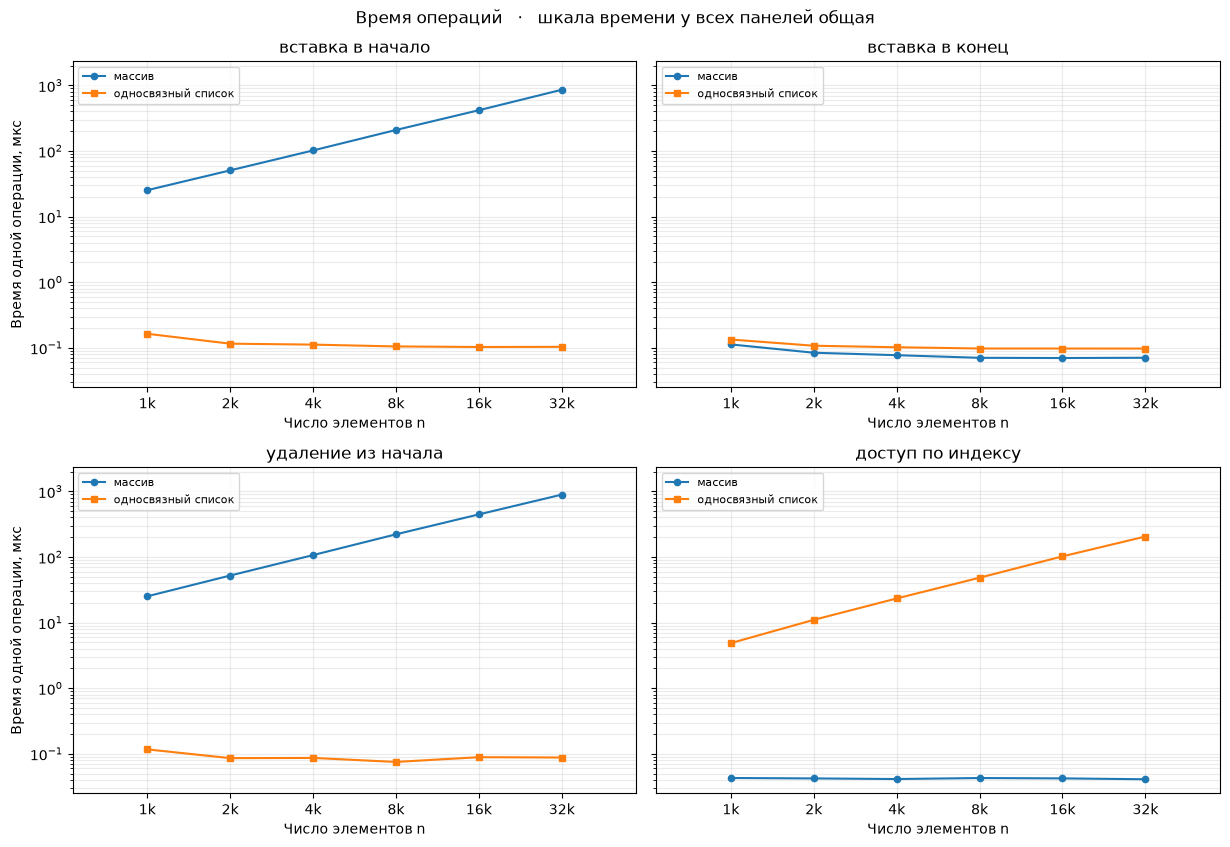

In [64]:
operations = lk.operations_table(FixedArray, LISTS)
lk.plot_operations(operations);

## Эксперимент 2. Две хеш-функции в таблице с цепочками

Таблица с цепочками заполняется по очереди с каждой из двух хеш-функций при
коэффициентах заполнения `0.25, 0.5, 0.7, 0.9`. Число слотов фиксировано и
простое, меняется только число ключей. Ключи — случайные строки одинаковой
длины. Сравниваются доля ключей с коллизией и время успешного и неуспешного
поиска.

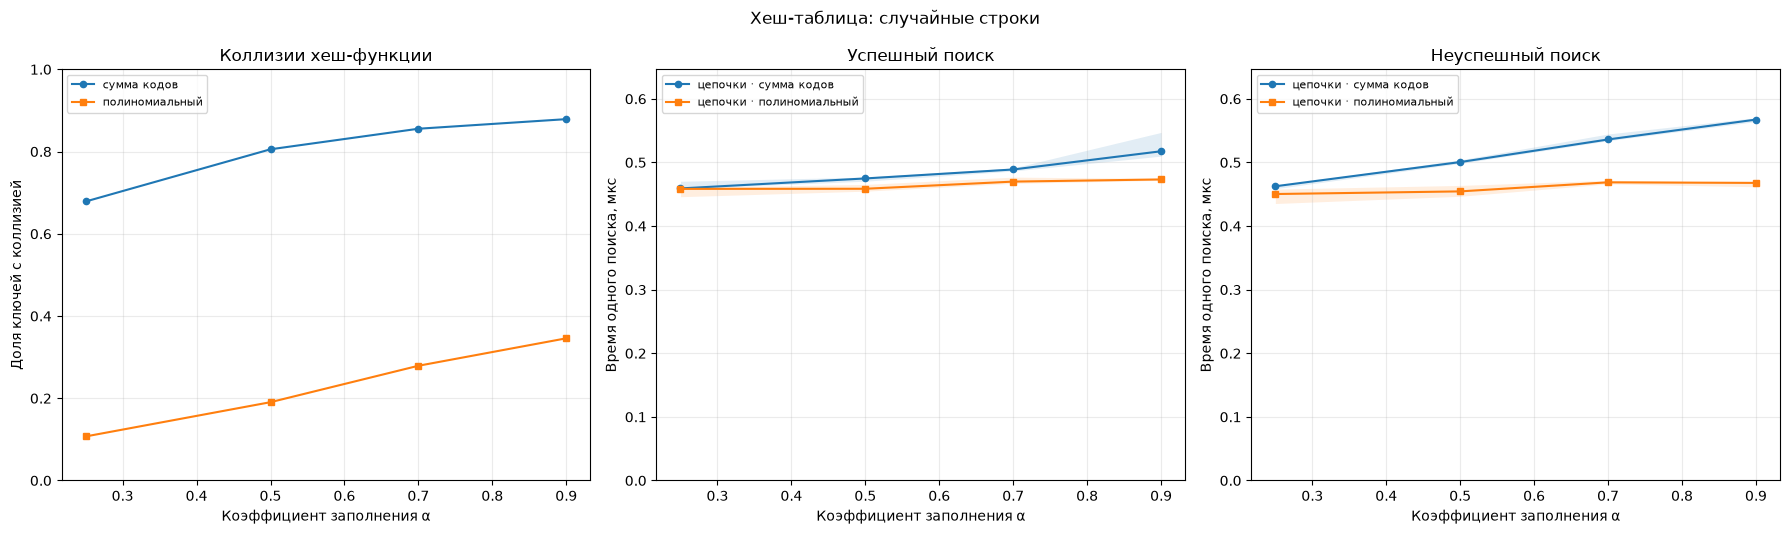

In [72]:
if TABLES and HASHES:
    random_keys = lk.hash_grid_table(TABLES, HASHES, "случайные строки")
    lk.plot_hash_grid(random_keys);
else:
    print("Хеш-таблица или хеш-функция не реализована — эксперимент пропущен")

## Самостоятельные выводы

Сформулируйте выводы по полученным графикам.

1. Как меняются затраты каждой операции массива и односвязного списка
   с размером структуры? Объясните различия по коду.
- для массива: вставка в начало и удаление из началаа - O(n) т.к. приходится проходить по всем остальным элементам и переносить их в соседние слоты; вставка в конец и доступ по индексу - O(1) т.к. мы просто обращаемся к предсказуемому элементу и не проходит по остальным элементам.
Для односвязного списка: вставка в начало / в конец и удаление первого элемента - O(1) т.к. мы просто работает с нодами на которые у нас уже есть указатели; доступ по индексу O(n) т.к. приходится проходить по всем элементам до индекса
2. Какие операции имеют примерно постоянное время, а какие растут вместе с `n`?
- впринципе чтобы было постоянное время (если не учитывать армотизированное) нужно заранее иметь всю необходимую информацию для выполнения алгоритма. Как только мы что-то не знаем точно и идём проверять, мы начинаем зависеть от размера входных данных и их характеристик.
3. Почему `push`, `pop` и `top` могут выполняться за ожидаемое `O(1)` в обоих
   стеках? Какой конец массива и списка должен играть роль вершины стека?
- потому что у нас есть конец массива, на котором, как я уже объяснил, действия выполняются за константное время т.к. мы знаем позицию конца и действия над ней не влияют на другие элементы. 
В случае списка мы берём для стека начало, т.к. мы всегда имеем указатель на него и на следующий элемент для замены при удалении (в случае с двусвязанными списками было бы не важно откуда начинать, там то же самое можно сказать и про конец)
4. Чем стек на массиве отличается от стека на связном списке по ограничению
   ёмкости, дополнительной памяти и размещению элементов в памяти? В каких
   условиях разумнее выбрать каждую реализацию?
- массивы неизменяемы, так что мы ограниченны размером, а списки можно продлевать сколько нужно. При этом в массиве элементы в памяти последовательны, из-за чего прохождение по ним предсказуемо и быстро, в списке элементы лежат рандомно, поэтому их вызов в памяти занимает больше времени. Кроме того, элемент массива занимет меньше места чем элемент списка, но при этом мы берём с самого начала весь объём масива даже если используем только пару слотов, когда список выделяет память динамически.
Впринципе стек на списке почти всегда разумнее с моей точки зрения, в большинстве реальных задач мы не можем точно сказать сколько элементов придётся на него поместить и удобней просто дать компьютеру выделять что нужно когда нужно. Главный плюс массивов в константном доступе по индексу, но в стеках нам на это более-менее наплевать.
5. Как выбор хеш-функции влияет на долю коллизий и время поиска случайных
   строк? Почему хеш с меньшим числом коллизий не обязательно быстрее при
   небольшой заполненности?
- выбор функций влияет на долю колизий т.к. полиномиальные хэши собирают большее число особенностей ключа, и из-за этого меньше дают те же хеши разным ключам.
при небольшой заполненности даже у простых хеш функций будет мало колизий, поэтому увеличенные затраты на лучшее хешированние не окупаются
6. Как устроена открытая адресация с линейным пробированием
   `i_j = (h(key) + j) % capacity` и почему поиск отсутствующего ключа можно
   остановить на первом свободном слоте?
- потому что мы записываем ключ в первый пустой слот по своему пробированию, если мы натыкаемся на пустой слот, значит ключ, при существовании, должен быть был записан раньше, и следственно, если мы его не нашли раньше, значит его просто нет
7. Как изменились бы графики успешного и неуспешного поиска, если вместо
   цепочек использовать линейное пробирование? Почему заполненность `0.9`
   особенно опасна из-за образования кластеров?
- при линейном пробировании время выполнения было бы ниже на меньшей заполненности и в разы хуже на большей заполненности (где-то 0.7 - 0.8 + ) т.к. линейн. проб. -это сплошные массивы (не уверен насчёт питона, но на плюсах это было бы вообще скорее всего на кэше процессора), а цепочки - связанные списки (при этом всегда на ram). 
Чем больше заполненность, тем больше кластер, тем выше вероятность, что след. элемент в него попадёт - и так накапливается ком, лина кластера растёт с заполнением, и при 0ю9 и выше она начинает расти слишком быстро и заполняет всю таблицу одним кластером